# Proyecto final – Modelos y Simulación de Sistemas II (UdeA)
## Notebook 3 · Reducción de dimensión (Sección 5 de la guía)

Objetivo: determinar si es posible **reducir la complejidad** del modelo final sin perder desempeño.

1. **Análisis individual de variables** (punto 9): capacidad discriminante de cada variable mediante índice de
   Fisher, correlación y AUC univariado (numéricas) e información mutua y V de Cramér (categóricas), con un umbral
   de ruido obtenido por permutación. Identificación de variables candidatas a eliminar.
2. **Extracción lineal con PCA** (punto 10).
3. **Extracción no lineal con UMAP** (punto 11).

En cada espacio de características se **reajustan los hiperparámetros** de los **2 mejores modelos** de la Sección 4.

> Requiere haber ejecutado el notebook 2 (lee `resultados/mejores_modelos.json`).
> Tiempo aproximado en Colab: 30–40 minutos.

## 1. Configuración del entorno

In [1]:
try:
    import umap.umap_ as umap
except ImportError:
    !pip -q install umap-learn
    import umap.umap_ as umap

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os, re, glob, json, time, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, ParameterGrid
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             recall_score, f1_score, balanced_accuracy_score)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
SEMILLA = 0

from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif

In [3]:
def buscar_carpeta_proyecto(raiz):
    """Busca la carpeta 'Proyecto_final' que contiene data_set/diabetic_data.csv (tolera tildes)."""
    for ruta in glob.glob(os.path.join(raiz, "**", "diabetic_data.csv"), recursive=True):
        ruta_n = unicodedata.normalize("NFC", ruta)
        if "Proyecto_final" in ruta_n:
            carpeta = os.path.dirname(ruta)
            return os.path.dirname(carpeta) if os.path.basename(carpeta) == "data_set" else carpeta
    return None

try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = None
    raiz = "/content/drive/MyDrive"
    candidatas = [os.path.join(raiz, d) for d in os.listdir(raiz)
                  if unicodedata.normalize("NFC", d).startswith("Modelos y Simulaci")]
    for c in candidatas + [raiz]:
        BASE_DIR = buscar_carpeta_proyecto(c)
        if BASE_DIR:
            break
except ImportError:
    BASE_DIR = os.environ.get("PROYECTO_DIR", ".")

if BASE_DIR is None:
    raise FileNotFoundError("No se encontró Proyecto_final/data_set/diabetic_data.csv en el Drive.")

DATA_DIR = os.path.join(BASE_DIR, "data_set")
RES_DIR = os.path.join(BASE_DIR, "resultados")
FIG_DIR = os.path.join(RES_DIR, "figuras")
os.makedirs(FIG_DIR, exist_ok=True)
print("Carpeta del proyecto:", BASE_DIR)

Carpeta del proyecto: /home/claude/proyecto/run


## 2. Datos, partición y particiones (idénticas al notebook 2: mismas semillas)

In [4]:
MEDS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
        "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
        "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
        "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]

def grupo_icd9(codigo):
    """Agrupa un código ICD-9 en 9 familias clínicas (Strack et al., 2014)."""
    if pd.isna(codigo):
        return "Missing"
    codigo = str(codigo)
    if codigo[0] in ("V", "E"):
        return "Other"
    x = float(codigo)
    if int(x) == 250:                              return "Diabetes"
    if 390 <= x <= 459 or int(x) == 785:           return "Circulatory"
    if 460 <= x <= 519 or int(x) == 786:           return "Respiratory"
    if 520 <= x <= 579 or int(x) == 787:           return "Digestive"
    if 800 <= x <= 999:                            return "Injury"
    if 710 <= x <= 739:                            return "Musculoskeletal"
    if 580 <= x <= 629 or int(x) == 788:           return "Genitourinary"
    if 140 <= x <= 239:                            return "Neoplasms"
    return "Other"

ADM_TYPE = {1: "Emergency", 2: "Urgent", 3: "Elective", 7: "Emergency",
            4: "Unknown", 5: "Unknown", 6: "Unknown", 8: "Unknown"}

def grupo_alta(i):
    if i == 1:              return "Home"
    if i in (6, 8):         return "Home health"
    if i == 7:              return "Left AMA"
    if i in (18, 25, 26):   return "Unknown"
    return "Transfer"

def grupo_fuente(i):
    if i in (1, 2, 3):                         return "Referral"
    if i == 7:                                 return "Emergency room"
    if i in (4, 5, 6, 10, 18, 22, 25, 26):     return "Transfer"
    return "Unknown"

def cargar_datos(ruta):
    """Lee el CSV original y aplica solo transformaciones fila a fila (no usan estadísticas
    del conjunto, por lo que no generan fuga de información).
    Retorna X (DataFrame), y (0/1) y grupos (patient_nbr)."""
    df = pd.read_csv(ruta, keep_default_na=False, na_values=["?"], low_memory=False)
    df = df[~df["discharge_disposition_id"].isin([11, 13, 14, 19, 20, 21])]   # fallecidos / hospicio
    df = df[df["gender"] != "Unknown/Invalid"].sort_values("encounter_id").reset_index(drop=True)
    y = (df["readmitted"] == "<30").astype(int).values
    grupos = df["patient_nbr"].values
    X = pd.DataFrame(index=df.index)
    X["race"] = df["race"].fillna("Missing")
    X["gender"] = (df["gender"] == "Male").astype(int)
    X["age"] = df["age"].map(lambda s: int(re.findall(r"\d+", s)[0]) // 10)
    X["admission_type"] = df["admission_type_id"].map(ADM_TYPE)
    X["discharge_disposition"] = df["discharge_disposition_id"].map(grupo_alta)
    X["admission_source"] = df["admission_source_id"].map(grupo_fuente)
    X["medical_specialty"] = df["medical_specialty"].fillna("Missing")
    for c in ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_diagnoses"]:
        X[c] = df[c]
    for c in ["number_outpatient", "number_emergency", "number_inpatient"]:
        X[c] = np.log1p(df[c])
    for c in ["diag_1", "diag_2", "diag_3"]:
        X[c] = df[c].map(grupo_icd9)
    X["max_glu_serum"] = df["max_glu_serum"]
    X["A1Cresult"] = df["A1Cresult"]
    X["change"] = (df["change"] == "Ch").astype(int)
    X["n_diab_meds"] = (df[MEDS] != "No").sum(axis=1)
    X["n_dose_changes"] = df[MEDS].isin(["Up", "Down"]).sum(axis=1)
    for m in MEDS:
        X[m] = df[m]
    # diabetesMed no se incluye: es redundante con n_diab_meds (diabetesMed = 1 <=> n_diab_meds > 0)
    return X, y, grupos


class Preprocesador(BaseEstimator, TransformerMixin):
    """Pasos que SÍ usan estadísticas de los datos; se ajustan solo con el conjunto de entrenamiento:
    - elimina medicamentos usados por menos del 0,1 % de las hospitalizaciones,
    - conserva las 10 especialidades más frecuentes (resto -> 'Other', faltante -> 'Missing'),
    - codificación one-hot de las variables nominales,
    - estandarización de las variables numéricas."""

    def __init__(self, umbral_med=0.001, top_esp=10, escalar=True):
        self.umbral_med = umbral_med
        self.top_esp = top_esp
        self.escalar = escalar

    def fit(self, X, y=None):
        self.meds_ = [m for m in MEDS if (X[m] != "No").mean() >= self.umbral_med]
        esp = X.loc[X["medical_specialty"] != "Missing", "medical_specialty"].value_counts()
        self.top_ = list(esp.index[: self.top_esp])
        self.cat_ = ["race", "admission_type", "discharge_disposition", "admission_source", "medical_specialty",
                     "diag_1", "diag_2", "diag_3", "max_glu_serum", "A1Cresult"] + self.meds_
        self.num_ = ["gender", "age", "time_in_hospital", "num_lab_procedures", "num_procedures",
                     "num_medications", "number_diagnoses", "number_outpatient", "number_emergency",
                     "number_inpatient", "change", "n_diab_meds", "n_dose_changes"]
        Z = self._especialidad(X)
        self.ohe_ = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(Z[self.cat_])
        self.scaler_ = StandardScaler().fit(Z[self.num_]) if self.escalar else None
        self.nombres_ = self.num_ + list(self.ohe_.get_feature_names_out(self.cat_))
        return self

    def _especialidad(self, X):
        Z = X.copy()
        Z["medical_specialty"] = np.where(Z["medical_specialty"].isin(self.top_ + ["Missing"]),
                                          Z["medical_specialty"], "Other")
        return Z

    def transform(self, X):
        Z = self._especialidad(X)
        num = Z[self.num_].values.astype(float)
        if self.scaler_ is not None:
            num = self.scaler_.transform(Z[self.num_])
        return np.hstack([num, self.ohe_.transform(Z[self.cat_])]).astype(np.float32)

In [5]:
X, y, grupos = cargar_datos(os.path.join(DATA_DIR, "diabetic_data.csv"))
print(f"Hospitalizaciones: {len(X):,} | pacientes: {len(np.unique(grupos)):,} | "
      f"variables: {X.shape[1]} | readmitidos <30 días: {y.mean()*100:.2f} %")

Hospitalizaciones: 99,340 | pacientes: 69,987 | variables: 46 | readmitidos <30 días: 11.39 %


In [6]:
# Partición entrenamiento+validación (80 %) / prueba (20 %), estratificada y POR PACIENTE:
# todas las hospitalizaciones de un paciente quedan en el mismo conjunto.
sgkf_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_dev, idx_test = next(sgkf_test.split(X, y, grupos))
X_dev, y_dev, g_dev = X.iloc[idx_dev].reset_index(drop=True), y[idx_dev], grupos[idx_dev]
X_test, y_test, g_test = X.iloc[idx_test].reset_index(drop=True), y[idx_test], grupos[idx_test]
assert len(set(g_dev) & set(g_test)) == 0, "Hay pacientes compartidos entre desarrollo y prueba"
print(f"Desarrollo: {len(X_dev):,} hospitalizaciones ({len(np.unique(g_dev)):,} pacientes), "
      f"{y_dev.mean()*100:.2f} % positivos")
print(f"Prueba:     {len(X_test):,} hospitalizaciones ({len(np.unique(g_test)):,} pacientes), "
      f"{y_test.mean()*100:.2f} % positivos")

def crear_particiones(X_dev, y_dev, g_dev, n_splits=5, semilla=1):
    """Validación cruzada estratificada por grupos sobre el conjunto de desarrollo.
    El preprocesador se ajusta SOLO con el fold de entrenamiento."""
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=semilla)
    particiones = []
    for tr, va in sgkf.split(X_dev, y_dev, g_dev):
        prep = Preprocesador().fit(X_dev.iloc[tr])
        particiones.append(dict(Xtr=prep.transform(X_dev.iloc[tr]), ytr=y_dev[tr],
                                Xva=prep.transform(X_dev.iloc[va]), yva=y_dev[va],
                                gva=g_dev[va], nombres=prep.nombres_))
    return particiones

Desarrollo: 79,472 hospitalizaciones (56,006 pacientes), 11.39 % positivos
Prueba:     19,868 hospitalizaciones (13,981 pacientes), 11.39 % positivos


In [7]:
def ic95(valores):
    """Media e intervalo de confianza del 95 % (t de Student) a partir de los folds."""
    v = np.asarray(valores, dtype=float)
    m = v.mean()
    h = stats.t.ppf(0.975, len(v) - 1) * v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0.0
    return m, h

def puntajes(modelo, X):
    """Puntaje continuo del modelo (probabilidad o distancia al hiperplano en la SVM)."""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)

def submuestra_estratificada(n_total, y, n, semilla):
    """Índices de una submuestra estratificada de tamaño n (para la SVM)."""
    rng = np.random.RandomState(semilla)
    idx = []
    for c in (0, 1):
        pos = np.where(y == c)[0]
        k = int(round(n * len(pos) / n_total))
        idx.append(rng.choice(pos, k, replace=False))
    return np.sort(np.concatenate(idx))

def umbral_youden(y_true, s):
    """Umbral que maximiza el índice de Youden J = sensibilidad + especificidad - 1."""
    fpr, tpr, thr = roc_curve(y_true, s)
    return thr[np.argmax(tpr - fpr)]

def metricas_umbral(y_true, s, umbral):
    yp = (s >= umbral).astype(int)
    return dict(sens=recall_score(y_true, yp), esp=recall_score(y_true, yp, pos_label=0),
                bacc=balanced_accuracy_score(y_true, yp), f1=f1_score(y_true, yp))

def experimentar(crear_modelo, malla, particiones, submuestra=None):
    """Recorre la malla de hiperparámetros con validación cruzada por grupos.
    crear_modelo: función que recibe los hiperparámetros y retorna un modelo sin entrenar.
    malla: dict con la lista de valores de cada hiperparámetro.
    submuestra: si no es None, cada modelo se entrena con esa cantidad de muestras del fold.
    Retorna un DataFrame con AUC de entrenamiento y validación (media e IC 95 %) y AUC-PR de validación."""
    resultados = pd.DataFrame()
    for idx, params in enumerate(ParameterGrid(malla)):
        auc_tr, auc_va, ap_va, tiempos = [], [], [], []
        for k, p in enumerate(particiones):
            Xtr, ytr = p["Xtr"], p["ytr"]
            if submuestra is not None:
                sel = submuestra_estratificada(len(ytr), ytr, min(submuestra, len(ytr)), semilla=k)
                Xtr, ytr = Xtr[sel], ytr[sel]
            modelo = crear_modelo(**params)
            t0 = time.time()
            modelo.fit(Xtr, ytr)
            tiempos.append(time.time() - t0)
            s_va = puntajes(modelo, p["Xva"])
            e = submuestra_estratificada(len(ytr), ytr, min(10000, len(ytr)), semilla=100 + k)
            auc_tr.append(roc_auc_score(ytr[e], puntajes(modelo, Xtr[e])))   # AUC de entrenamiento en 10 000 muestras
            auc_va.append(roc_auc_score(p["yva"], s_va))
            ap_va.append(average_precision_score(p["yva"], s_va))
        fila = dict(params)
        fila["AUC entrenamiento"], fila["IC entrenamiento"] = ic95(auc_tr)
        fila["AUC validación"], fila["IC validación"] = ic95(auc_va)
        fila["AUC-PR validación"], fila["IC AUC-PR"] = ic95(ap_va)
        fila["tiempo (s)"] = np.mean(tiempos)
        resultados = pd.concat([resultados, pd.DataFrame([fila])], ignore_index=True)
    return resultados

def predicciones_validacion(crear_modelo, params, particiones, submuestra=None):
    """Entrena la configuración elegida en cada fold y retorna los puntajes de validación,
    para elegir el umbral y calcular métricas dependientes del umbral con su IC."""
    salida = []
    for k, p in enumerate(particiones):
        Xtr, ytr = p["Xtr"], p["ytr"]
        if submuestra is not None:
            sel = submuestra_estratificada(len(ytr), ytr, min(submuestra, len(ytr)), semilla=k)
            Xtr, ytr = Xtr[sel], ytr[sel]
        modelo = crear_modelo(**params).fit(Xtr, ytr)
        e = submuestra_estratificada(len(ytr), ytr, min(10000, len(ytr)), semilla=100 + k)
        salida.append(dict(s_tr=puntajes(modelo, Xtr[e]), ytr=ytr[e], s_va=puntajes(modelo, p["Xva"]), yva=p["yva"]))
    return salida

def bootstrap_por_paciente(y_true, s, grupos_test, umbral, n_boot=1000, semilla=0):
    """IC 95 % en prueba remuestreando PACIENTES con reemplazo (percentiles 2,5 y 97,5)."""
    rng = np.random.RandomState(semilla)
    pacientes, inv = np.unique(grupos_test, return_inverse=True)
    filas_por_paciente = pd.Series(np.arange(len(inv))).groupby(inv).apply(np.array).values
    reg = {k: [] for k in ["auc", "ap", "sens", "esp", "bacc", "f1"]}
    for _ in range(n_boot):
        elegidos = rng.randint(0, len(pacientes), len(pacientes))
        idx = np.concatenate([filas_por_paciente[i] for i in elegidos])
        yt, st = y_true[idx], s[idx]
        reg["auc"].append(roc_auc_score(yt, st)); reg["ap"].append(average_precision_score(yt, st))
        for k, v in metricas_umbral(yt, st, umbral).items():
            reg[k].append(v)
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in reg.items()}

## 3. Los dos mejores modelos de la Sección 4

In [8]:
with open(os.path.join(RES_DIR, "mejores_modelos.json"), encoding="utf-8") as f:
    MEJORES = json.load(f)
resumen_cv = pd.read_csv(os.path.join(RES_DIR, "resumen_validacion.csv"))
TOP2 = resumen_cv.sort_values("AUC val.", ascending=False)["modelo"].head(2).tolist()
print("Dos mejores modelos (AUC de validación):", TOP2)
for m in TOP2:
    print(f"  {m}: {MEJORES[m]['params']}  AUC val = {MEJORES[m]['auc_val']:.4f} ± {MEJORES[m]['ic_val']:.4f}")

Dos mejores modelos (AUC de validación): ['Random Forest', 'Gradient Boosting']
  Random Forest: {'n_estimators': 300, 'min_samples_leaf': 10}  AUC val = 0.6672 ± 0.0070
  Gradient Boosting: {'learning_rate': 0.03, 'max_leaf_nodes': 31}  AUC val = 0.6666 ± 0.0087


In [9]:
# Constructores de modelos (los mismos del notebook 2) y mallas reducidas para el reajuste
def crear_lr(C):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=2000)
def crear_knn(n_neighbors, weights):
    return KNeighborsClassifier(n_neighbors=n_neighbors, weights=weights, n_jobs=-1)
def crear_rf(n_estimators, min_samples_leaf):
    return RandomForestClassifier(n_estimators=n_estimators, min_samples_leaf=min_samples_leaf, max_features="sqrt",
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=SEMILLA)
def crear_gb(learning_rate, max_leaf_nodes):
    return HistGradientBoostingClassifier(learning_rate=learning_rate, max_leaf_nodes=max_leaf_nodes,
                                          max_iter=200, class_weight="balanced", random_state=SEMILLA)
def crear_mlp(hidden_layer_sizes, alpha):
    return MLPClassifier(hidden_layer_sizes=hidden_layer_sizes, alpha=alpha, early_stopping=True,
                         max_iter=300, random_state=SEMILLA)
def crear_svm(C, gamma):
    return SVC(C=C, gamma=gamma, kernel="rbf", class_weight="balanced")

CONSTRUCTORES = {"Regresión logística": (crear_lr, None), "k-NN": (crear_knn, None),
                 "Random Forest": (crear_rf, None), "Gradient Boosting": (crear_gb, None),
                 "MLP": (crear_mlp, None), "SVM (RBF)": (crear_svm, 8000)}

# Mallas de reajuste: centradas en la región que funcionó mejor en la Sección 4
MALLAS_REAJUSTE = {
    "Regresión logística": {"C": [0.01, 0.1, 1]},
    "k-NN": {"n_neighbors": [75, 150, 300], "weights": ["uniform"]},
    "Random Forest": {"n_estimators": [200], "min_samples_leaf": [10, 50]},
    "Gradient Boosting": {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [7, 31]},
    "MLP": {"hidden_layer_sizes": [(16,), (64,)], "alpha": [1e-2, 1e-1]},
    "SVM (RBF)": {"C": [0.1, 1], "gamma": ["scale"]},
}

def reajustar(nombre, particiones_espacio):
    # Reajusta los hiperparámetros de un modelo en un nuevo espacio de características
    crear, sub = CONSTRUCTORES[nombre]
    res = experimentar(crear, MALLAS_REAJUSTE[nombre], particiones_espacio, submuestra=sub)
    if "hidden_layer_sizes" in res:
        res["hidden_layer_sizes"] = res["hidden_layer_sizes"].astype(str)
    return res.sort_values("AUC validación", ascending=False).reset_index(drop=True)

def parametros_de_fila(fila, malla):
    # Recupera los hiperparámetros de una fila de resultados con su tipo original (pandas convierte int -> float)
    params = {}
    for k, valores in malla.items():
        v = fila[k]
        params[k] = next(c for c in valores if str(c) == str(v) or
                         (not isinstance(c, (str, tuple)) and not isinstance(v, str) and np.isclose(c, v)))
    return params

particiones = crear_particiones(X_dev, y_dev, g_dev, n_splits=5, semilla=1)
NOMBRES = particiones[0]["nombres"]
print("Folds listos. Dimensión original (tras one-hot):", particiones[0]["Xtr"].shape[1])

Folds listos. Dimensión original (tras one-hot): 126


## 4. Análisis individual de variables (5.1)

Se analizan las **36 variables originales** (antes del one-hot) sobre el conjunto de **desarrollo** (no se usa el
conjunto de prueba):

| Tipo | Medidas | Interpretación |
|---|---|---|
| Numéricas (13) | Índice de Fisher $F = \frac{(\mu_1-\mu_0)^2}{\sigma_1^2+\sigma_0^2}$, correlación de Spearman con $y$, AUC univariado | Separación entre las medias de las clases relativa a su dispersión; relación monótona; capacidad de ordenar por sí sola |
| Categóricas (23) | Información mutua $I(X;Y)$ y V de Cramér | Reducción de la incertidumbre sobre $y$ al conocer la variable (captura relaciones no lineales); asociación normalizada en [0, 1] |

**Criterio de "candidata a eliminar":** se compara cada medida con su **distribución bajo la hipótesis nula**,
obtenida al permutar aleatoriamente la etiqueta $y$ (50 permutaciones). Una variable es candidata si su medida no
supera el percentil 99 de la nula: es decir, si su relación con la readmisión **no se distingue del ruido**. Este
criterio no depende de un umbral arbitrario.

In [10]:
def fisher(x, y):
    a, b = x[y == 1], x[y == 0]
    return (a.mean() - b.mean()) ** 2 / (a.var() + b.var())

def v_cramer(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(tabla, correction=False)[0]
    return np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))

def info_mutua(x, y):
    codigos = pd.factorize(x)[0].reshape(-1, 1)
    return mutual_info_classif(codigos, y, discrete_features=True, random_state=SEMILLA)[0]

num_vars = ["gender", "age", "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_diagnoses", "number_outpatient", "number_emergency", "number_inpatient", "change",
            "n_diab_meds", "n_dose_changes"]
cat_vars = [c for c in X_dev.columns if c not in num_vars]

rng = np.random.RandomState(SEMILLA)
N_PERM = 50
y_perm = [rng.permutation(y_dev) for _ in range(N_PERM)]

filas = []
t0 = time.time()
for v in num_vars:
    x = X_dev[v].values.astype(float)
    f = fisher(x, y_dev); r = stats.spearmanr(x, y_dev)[0]; auc = roc_auc_score(y_dev, x)
    nula = np.percentile([fisher(x, yp) for yp in y_perm], 99)
    filas.append(dict(variable=v, tipo="numérica", **{"Fisher": f, "Spearman": r, "AUC univariado": max(auc, 1 - auc),
                      "umbral nulo (p99)": nula, "candidata a eliminar": f <= nula}))
for v in cat_vars:
    x = X_dev[v].astype(str).values
    mi = info_mutua(x, y_dev); vc = v_cramer(x, y_dev)
    nula = np.percentile([info_mutua(x, yp) for yp in y_perm], 99)
    filas.append(dict(variable=v, tipo="categórica", **{"Información mutua": mi, "V de Cramér": vc,
                      "umbral nulo (p99)": nula, "candidata a eliminar": mi <= nula}))
analisis = pd.DataFrame(filas)
print(f"Análisis individual en {time.time()-t0:.0f} s")
analisis_num = analisis[analisis.tipo == "numérica"].dropna(axis=1, how="all").sort_values("Fisher", ascending=False)
analisis_cat = analisis[analisis.tipo == "categórica"].dropna(axis=1, how="all").sort_values("Información mutua", ascending=False)
display(analisis_num.round(5))
display(analisis_cat.round(5))
CANDIDATAS = analisis.loc[analisis["candidata a eliminar"], "variable"].tolist()
print("Variables candidatas a eliminar:", CANDIDATAS)

Análisis individual en 22 s


,variable,tipo,Fisher,Spearman,AUC univariado,umbral nulo (p99),candidata a eliminar
9,number_inpatient,numérica,0.10584,0.14458,0.60956,0.00043,False
8,number_emergency,numérica,0.02160,0.06632,0.53309,0.00033,False
6,number_diagnoses,numérica,0.01428,0.04992,0.54263,0.00040,False
2,time_in_hospital,numérica,0.00990,0.05142,0.54632,0.00039,False
5,num_medications,numérica,0.00766,0.04637,0.54210,0.00028,False
12,n_dose_changes,numérica,0.00652,0.03892,0.52736,0.00045,False
7,number_outpatient,numérica,0.00407,0.03417,0.52008,0.00031,False
3,num_lab_procedures,numérica,0.00301,0.02493,0.52265,0.00028,False
10,change,numérica,0.00186,0.01940,0.51523,0.00040,False
1,age,numérica,0.00174,0.02099,0.51871,0.00030,False


,variable,tipo,umbral nulo (p99),candidata a eliminar,Información mutua,V de Cramér
15,discharge_disposition,categórica,0.00008,False,0.00365,0.08776
17,medical_specialty,categórica,0.00058,False,0.00214,0.06297
40,insulin,categórica,0.00007,False,0.00106,0.04675
20,diag_3,categórica,0.00011,False,0.00056,0.03346
18,diag_1,categórica,0.00012,False,0.00049,0.03168
23,metformin,categórica,0.00006,False,0.00035,0.02600
19,diag_2,categórica,0.00014,False,0.00032,0.02606
16,admission_source,categórica,0.00007,False,0.00026,0.02277
22,A1Cresult,categórica,0.00006,False,0.00026,0.02233
13,race,categórica,0.00011,False,0.00018,0.01830


Variables candidatas a eliminar: ['gender', 'n_diab_meds', 'repaglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone']


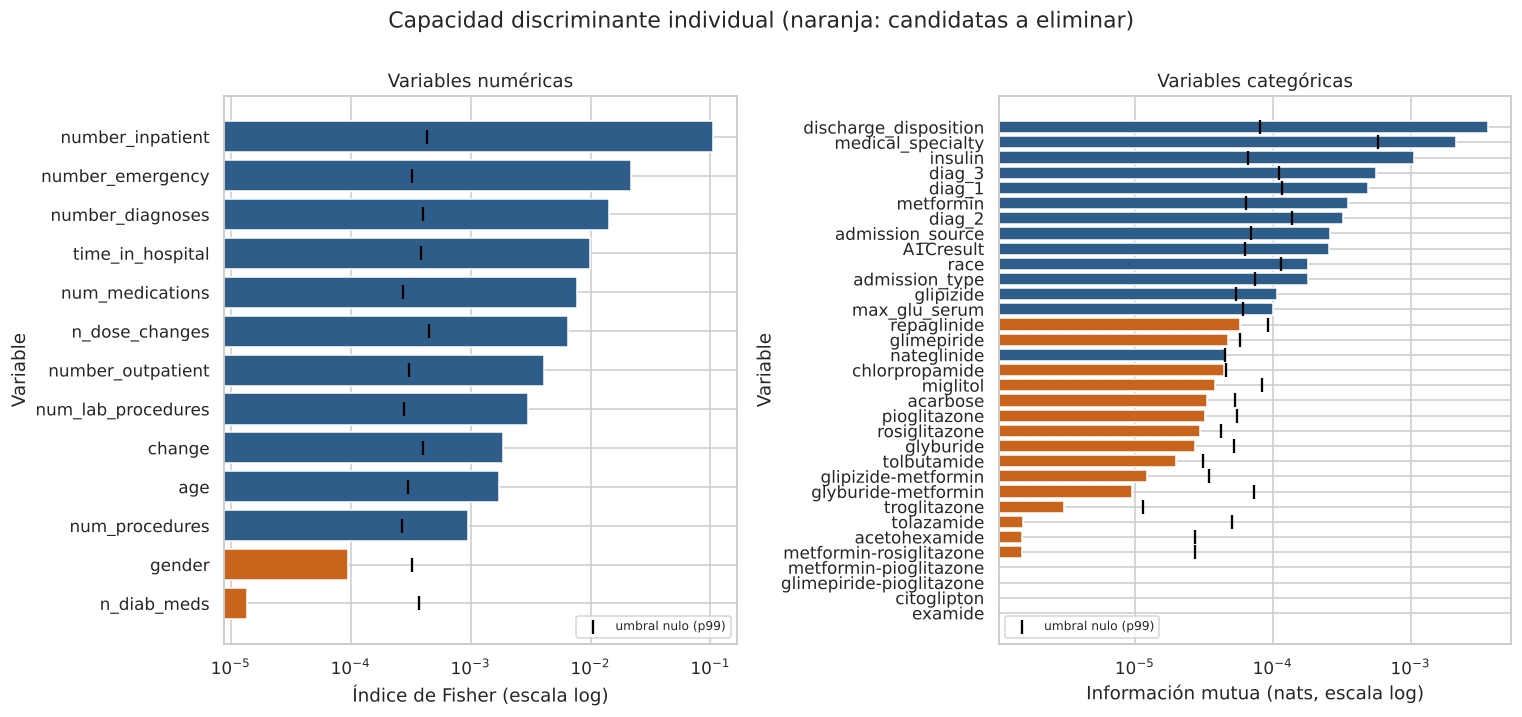

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
d = analisis_num.sort_values("Fisher")
axes[0].barh(d["variable"], d["Fisher"], color=np.where(d["candidata a eliminar"], "#c8641b", "#2f5d8a"))
axes[0].scatter(d["umbral nulo (p99)"], d["variable"], marker="|", color="black", s=80, label="umbral nulo (p99)")
axes[0].legend(fontsize=8)
axes[0].set_xscale("log"); axes[0].set_xlabel("Índice de Fisher (escala log)"); axes[0].set_ylabel("Variable")
axes[0].set_title("Variables numéricas")
d = analisis_cat.sort_values("Información mutua")
axes[1].barh(d["variable"], d["Información mutua"], color=np.where(d["candidata a eliminar"], "#c8641b", "#2f5d8a"))
axes[1].scatter(d["umbral nulo (p99)"], d["variable"], marker="|", color="black", s=80, label="umbral nulo (p99)")
axes[1].set_xscale("log"); axes[1].set_xlabel("Información mutua (nats, escala log)"); axes[1].set_ylabel("Variable")
axes[1].set_title("Variables categóricas"); axes[1].legend(fontsize=8)
plt.suptitle("Capacidad discriminante individual (naranja: candidatas a eliminar)", y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "analisis_individual.pdf"), bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "analisis_individual.png"), dpi=150, bbox_inches="tight")
plt.show()

### 4.1 Redundancia entre predictoras

Además de la relación con $y$, se revisa si hay pares de variables que aportan la misma información
(correlación de Spearman entre numéricas y V de Cramér entre categóricas).

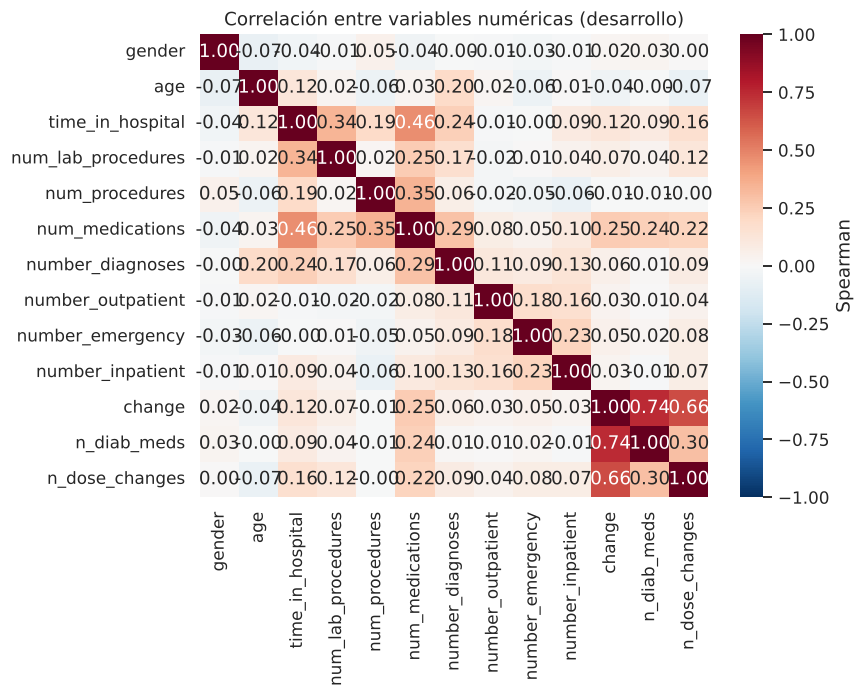

,variable 1,variable 2,V de Cramér
12,admission_type,admission_source,0.581
34,admission_source,max_glu_serum,0.351
13,admission_type,medical_specialty,0.327
17,admission_type,max_glu_serum,0.312
30,admission_source,medical_specialty,0.308
38,medical_specialty,diag_1,0.256
51,diag_2,diag_3,0.201
45,diag_1,diag_2,0.200


In [12]:
corr = X_dev[num_vars].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman"})
ax.set_title("Correlación entre variables numéricas (desarrollo)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "correlacion_numericas.png"), dpi=150, bbox_inches="tight"); plt.show()

pares = []
cats_principales = ["race", "admission_type", "discharge_disposition", "admission_source", "medical_specialty",
                    "diag_1", "diag_2", "diag_3", "max_glu_serum", "A1Cresult", "insulin", "metformin"]
for i, a in enumerate(cats_principales):
    for b in cats_principales[i + 1:]:
        pares.append((a, b, v_cramer(X_dev[a].astype(str), X_dev[b].astype(str))))
pares = pd.DataFrame(pares, columns=["variable 1", "variable 2", "V de Cramér"]).sort_values("V de Cramér", ascending=False)
pares.head(8).round(3)

### 4.2 Evaluación sin las variables candidatas

Se eliminan las variables candidatas y se **reajustan** los dos mejores modelos.

In [13]:
def particiones_sin(variables, X_dev, y_dev, g_dev):
    # Repite las particiones (mismas semillas) eliminando las columnas one-hot de las variables indicadas
    nuevas = []
    for p in particiones:
        mascara = np.array([not any(n == v or n.startswith(v + "_") for v in variables) for n in p["nombres"]])
        nuevas.append(dict(p, Xtr=p["Xtr"][:, mascara], Xva=p["Xva"][:, mascara],
                           nombres=[n for n, m in zip(p["nombres"], mascara) if m]))
    return nuevas

part_sel = particiones_sin(CANDIDATAS, X_dev, y_dev, g_dev)
d_sel = part_sel[0]["Xtr"].shape[1]
print(f"Dimensión: {particiones[0]['Xtr'].shape[1]} -> {d_sel} "
      f"({(1 - d_sel / particiones[0]['Xtr'].shape[1]) * 100:.1f} % de reducción)")
RES_REDUCCION = []   # (modelo, espacio, n_dim, DataFrame de reajuste)
for nombre in TOP2:
    t0 = time.time()
    res = reajustar(nombre, part_sel)
    print(f"{nombre}: {time.time()-t0:.0f} s"); display(res.round(4))
    RES_REDUCCION.append((nombre, "Selección individual", d_sel, res))

Dimensión: 126 -> 96 (23.8 % de reducción)


Random Forest: 52 s


,min_samples_leaf,n_estimators,AUC entrenamiento,IC entrenamiento,AUC validación,IC validación,AUC-PR validación,IC AUC-PR,tiempo (s)
0,10,200,0.9371,0.0020,0.6670,0.0061,0.2109,0.0127,5.8041
1,50,200,0.7519,0.0031,0.6667,0.0073,0.2095,0.0134,3.8723


Gradient Boosting: 38 s


,learning_rate,max_leaf_nodes,AUC entrenamiento,IC entrenamiento,AUC validación,IC validación,AUC-PR validación,IC AUC-PR,tiempo (s)
0,0.03,31,0.7131,0.0086,0.6663,0.0090,0.2148,0.0161,2.7023
1,0.10,31,0.7177,0.0051,0.6646,0.0092,0.2139,0.0157,1.1170
2,0.10,7,0.6758,0.0145,0.6623,0.0094,0.2129,0.0152,1.2072
3,0.03,7,0.6685,0.0037,0.6618,0.0099,0.2123,0.0159,2.2494


## 5. Extracción lineal de características: PCA (5.2)

PCA proyecta los datos (estandarizados y codificados) sobre las direcciones de máxima varianza. El PCA se
**ajusta dentro de cada fold** con los datos de entrenamiento.

**Criterio para el número de componentes:** se usa la **varianza explicada acumulada**. Se evalúan los números de
componentes que conservan el 80 %, 90 % y 95 % de la varianza; el 90 % es el criterio principal (compromiso
habitual entre información retenida y reducción). Como la codificación one-hot genera muchas variables binarias
poco correlacionadas, se espera que se necesiten bastantes componentes.

Componentes necesarios (fold 0): {'80 %': 21, '90 %': 34, '95 %': 46} de 126


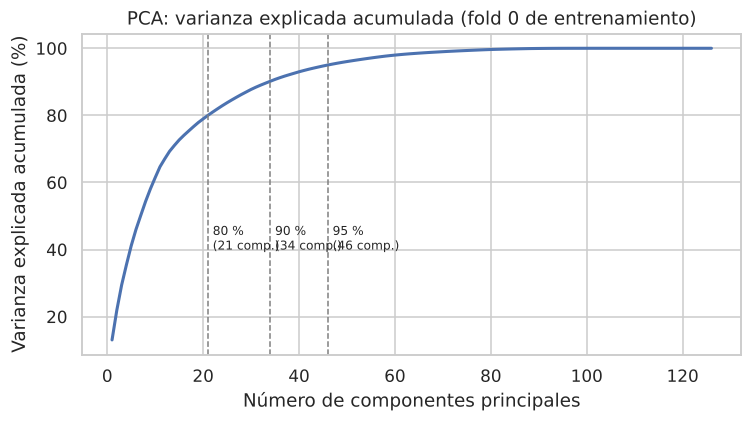

In [14]:
pca_ref = PCA().fit(particiones[0]["Xtr"])
var_acum = np.cumsum(pca_ref.explained_variance_ratio_)
N_COMP = {f"{int(p*100)} %": int(np.searchsorted(var_acum, p) + 1) for p in [0.80, 0.90, 0.95]}
print("Componentes necesarios (fold 0):", N_COMP, "de", particiones[0]["Xtr"].shape[1])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(var_acum) + 1), var_acum * 100, lw=2)
for etiqueta, n in N_COMP.items():
    ax.axvline(n, ls="--", color="gray", lw=1)
    ax.text(n + 1, 40, f"{etiqueta}\n({n} comp.)", fontsize=8)
ax.set_xlabel("Número de componentes principales"); ax.set_ylabel("Varianza explicada acumulada (%)")
ax.set_title("PCA: varianza explicada acumulada (fold 0 de entrenamiento)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "pca_varianza.pdf"), bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "pca_varianza.png"), dpi=150, bbox_inches="tight")
plt.show()

In [15]:
def particiones_pca(n_componentes):
    nuevas = []
    for p in particiones:
        pca = PCA(n_components=n_componentes, random_state=SEMILLA).fit(p["Xtr"])
        nuevas.append(dict(p, Xtr=pca.transform(p["Xtr"]).astype(np.float32),
                           Xva=pca.transform(p["Xva"]).astype(np.float32)))
    return nuevas

for etiqueta, n in N_COMP.items():
    part_pca = particiones_pca(n)
    for nombre in TOP2:
        t0 = time.time()
        res = reajustar(nombre, part_pca)
        print(f"PCA {etiqueta} ({n} comp.) · {nombre}: mejor AUC val = {res.loc[0, 'AUC validación']:.4f} "
              f"± {res.loc[0, 'IC validación']:.4f}  ({time.time()-t0:.0f} s)")
        RES_REDUCCION.append((nombre, f"PCA {etiqueta} varianza", n, res))

PCA 80 % (21 comp.) · Random Forest: mejor AUC val = 0.6530 ± 0.0114  (204 s)


PCA 80 % (21 comp.) · Gradient Boosting: mejor AUC val = 0.6509 ± 0.0103  (91 s)


PCA 90 % (34 comp.) · Random Forest: mejor AUC val = 0.6580 ± 0.0104  (256 s)


PCA 90 % (34 comp.) · Gradient Boosting: mejor AUC val = 0.6566 ± 0.0110  (131 s)


PCA 95 % (46 comp.) · Random Forest: mejor AUC val = 0.6591 ± 0.0098  (291 s)


PCA 95 % (46 comp.) · Gradient Boosting: mejor AUC val = 0.6573 ± 0.0106  (179 s)


## 6. Extracción no lineal de características: UMAP (5.3)

UMAP construye un grafo de vecinos cercanos en el espacio original y busca una representación de baja dimensión
que preserve esa estructura local. Se usa `umap-learn` (como en la Clase 22 del curso) con `n_neighbors=15` y
`min_dist=0.1` (valores por defecto recomendados).

**Criterio para el número de componentes:** UMAP no tiene una medida de varianza explicada, así que el número de
componentes se trata como un hiperparámetro: se evalúan 2, 5 y 10 componentes y se elige el de mayor AUC de
validación.

**Restricción computacional:** ajustar UMAP sobre ~63 000 muestras en cada fold y para cada número de componentes
es muy costoso. Por eso en cada fold UMAP se **ajusta con una submuestra estratificada de 10 000 hospitalizaciones
del fold de entrenamiento** y luego se usa para **transformar** el fold completo de entrenamiento y el de
validación. Los modelos sí se entrenan con todo el fold transformado.

In [16]:
def particiones_umap(n_componentes, n_ajuste=10000):
    nuevas = []
    for k, p in enumerate(particiones):
        sel = submuestra_estratificada(len(p["ytr"]), p["ytr"], min(n_ajuste, len(p["ytr"])), semilla=k)
        reductor = umap.UMAP(n_components=n_componentes, n_neighbors=15, min_dist=0.1, random_state=SEMILLA)
        reductor.fit(p["Xtr"][sel])
        nuevas.append(dict(p, Xtr=reductor.transform(p["Xtr"]).astype(np.float32),
                           Xva=reductor.transform(p["Xva"]).astype(np.float32)))
    return nuevas

for n in [2, 5, 10]:
    t0 = time.time()
    part_umap = particiones_umap(n)
    print(f"UMAP {n} componentes: transformación en {time.time()-t0:.0f} s")
    for nombre in TOP2:
        res = reajustar(nombre, part_umap)
        print(f"  {nombre}: mejor AUC val = {res.loc[0, 'AUC validación']:.4f} ± {res.loc[0, 'IC validación']:.4f}")
        RES_REDUCCION.append((nombre, f"UMAP {n} componentes", n, res))

UMAP 2 componentes: transformación en 91 s


  Random Forest: mejor AUC val = 0.5859 ± 0.0049


  Gradient Boosting: mejor AUC val = 0.5981 ± 0.0086


UMAP 5 componentes: transformación en 80 s


  Random Forest: mejor AUC val = 0.6143 ± 0.0084


  Gradient Boosting: mejor AUC val = 0.6193 ± 0.0069


UMAP 10 componentes: transformación en 99 s


  Random Forest: mejor AUC val = 0.6212 ± 0.0050


  Gradient Boosting: mejor AUC val = 0.6216 ± 0.0073


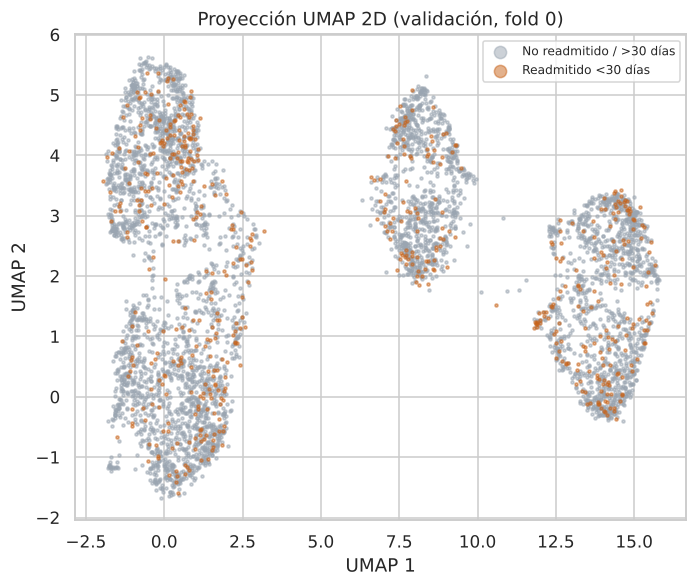

In [17]:
# Visualización: las dos primeras componentes de UMAP (2D) para una submuestra de validación del fold 0
p = particiones[0]
sel = submuestra_estratificada(len(p["ytr"]), p["ytr"], min(10000, len(p["ytr"])), semilla=0)
red2 = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEMILLA).fit(p["Xtr"][sel])
vis = submuestra_estratificada(len(p["yva"]), p["yva"], min(5000, len(p["yva"])), semilla=1)
Z = red2.transform(p["Xva"][vis])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for c, color, etiqueta in [(0, "#9aa5b1", "No readmitido / >30 días"), (1, "#c8641b", "Readmitido <30 días")]:
    m = p["yva"][vis] == c
    ax.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.5, color=color, label=etiqueta)
ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2"); ax.set_title("Proyección UMAP 2D (validación, fold 0)")
ax.legend(markerscale=4, fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "umap_2d.png"), dpi=150, bbox_inches="tight"); plt.show()

## 7. Comparación final y evaluación en prueba

Para cada modelo y espacio de características se toma la mejor configuración (mayor AUC de validación), se
reentrena con todo el conjunto de desarrollo (el reductor también se ajusta solo con desarrollo) y se evalúa en
prueba con IC por *bootstrap* de pacientes. Se incluye como referencia el espacio original (Sección 4).

In [18]:
prep_final = Preprocesador().fit(X_dev)
A_dev, A_test = prep_final.transform(X_dev), prep_final.transform(X_test)
D_ORIG = A_dev.shape[1]

def transformador_final(espacio, n):
    # Ajusta la reducción con TODO el conjunto de desarrollo y retorna (A_dev, A_test) transformados
    if espacio == "Original":
        return A_dev, A_test
    if espacio.startswith("Selección"):
        m = np.array([not any(nm == v or nm.startswith(v + "_") for v in CANDIDATAS) for nm in prep_final.nombres_])
        return A_dev[:, m], A_test[:, m]
    if espacio.startswith("PCA"):
        pca = PCA(n_components=n, random_state=SEMILLA).fit(A_dev)
        return pca.transform(A_dev).astype(np.float32), pca.transform(A_test).astype(np.float32)
    sel = submuestra_estratificada(len(y_dev), y_dev, min(10000, len(y_dev)), semilla=0)
    red = umap.UMAP(n_components=n, n_neighbors=15, min_dist=0.1, random_state=SEMILLA).fit(A_dev[sel])
    return red.transform(A_dev).astype(np.float32), red.transform(A_test).astype(np.float32)

# Referencia: espacio original con los hiperparámetros de la Sección 4
filas_cv = []
for nombre in TOP2:
    params = MEJORES[nombre]["params"]
    if "hidden_layer_sizes" in params:
        params["hidden_layer_sizes"] = tuple(params["hidden_layer_sizes"])
    filas_cv.append(dict(modelo=nombre, espacio="Original", n_dim=D_ORIG, params=params,
                         auc_val=MEJORES[nombre]["auc_val"], ic_val=MEJORES[nombre]["ic_val"]))
for nombre, espacio, n, res in RES_REDUCCION:
    mejor = res.iloc[0]
    filas_cv.append(dict(modelo=nombre, espacio=espacio, n_dim=n,
                         params=parametros_de_fila(mejor, MALLAS_REAJUSTE[nombre]),
                         auc_val=mejor["AUC validación"], ic_val=mejor["IC validación"],
                         auc_tr=mejor["AUC entrenamiento"], ic_tr=mejor["IC entrenamiento"]))
comparacion = pd.DataFrame(filas_cv)

filas = []
cache = {}
for _, f in comparacion.iterrows():
    clave = (f["espacio"], f["n_dim"])
    if clave not in cache:
        cache[clave] = transformador_final(f["espacio"], f["n_dim"])
    Ad, At = cache[clave]
    crear, sub = CONSTRUCTORES[f["modelo"]]
    Xa, ya = Ad, y_dev
    if sub is not None:
        s_ = submuestra_estratificada(len(ya), ya, min(sub, len(ya)), semilla=SEMILLA); Xa, ya = Xa[s_], ya[s_]
    t0 = time.time()
    modelo = crear(**f["params"]).fit(Xa, ya)
    t_fit = time.time() - t0
    s = puntajes(modelo, At)
    ic = bootstrap_por_paciente(y_test, s, g_test, np.median(s), n_boot=1000, semilla=SEMILLA)  # solo se usa el IC del AUC
    filas.append(dict(modelo=f["modelo"], espacio=f["espacio"], dimensiones=int(f["n_dim"]),
                      **{"reducción (%)": (1 - f["n_dim"] / D_ORIG) * 100,
                         "AUC val.": f["auc_val"], "IC val.": f["ic_val"],
                         "AUC prueba": roc_auc_score(y_test, s), "IC prueba": f"[{ic['auc'][0]:.3f}, {ic['auc'][1]:.3f}]",
                         "AUC-PR prueba": average_precision_score(y_test, s),
                         "IC AUC-PR prueba": f"[{ic['ap'][0]:.3f}, {ic['ap'][1]:.3f}]",
                         "tiempo entrenamiento (s)": t_fit, "hiperparámetros": str(f["params"])}))
tabla_reduccion = pd.DataFrame(filas)
tabla_reduccion.round(4)

,modelo,espacio,dimensiones,reducción (%),AUC val.,IC val.,AUC prueba,IC prueba,AUC-PR prueba,IC AUC-PR prueba,tiempo entrenamiento (s),hiperparámetros
0,Random Forest,Original,126,0.0000,0.6672,0.0070,0.6620,"[0.650, 0.674]",0.1987,"[0.182, 0.216]",11.3197,"{'n_estimators': 300, 'min_samples_leaf': 10}"
1,Gradient Boosting,Original,126,0.0000,0.6666,0.0087,0.6608,"[0.648, 0.673]",0.2015,"[0.185, 0.219]",2.9010,"{'learning_rate': 0.03, 'max_leaf_nodes': 31}"
2,Random Forest,Selección individual,96,23.8095,0.6670,0.0061,0.6648,"[0.652, 0.677]",0.2019,"[0.185, 0.219]",6.8062,"{'n_estimators': 200, 'min_samples_leaf': 10}"
3,Gradient Boosting,Selección individual,96,23.8095,0.6663,0.0090,0.6600,"[0.647, 0.672]",0.2021,"[0.185, 0.220]",2.4534,"{'learning_rate': 0.03, 'max_leaf_nodes': 31}"
4,Random Forest,PCA 80 % varianza,21,83.3333,0.6530,0.0114,0.6507,"[0.638, 0.664]",0.1965,"[0.179, 0.214]",24.8867,"{'n_estimators': 200, 'min_samples_leaf': 50}"
5,Gradient Boosting,PCA 80 % varianza,21,83.3333,0.6509,0.0103,0.6471,"[0.635, 0.660]",0.1902,"[0.174, 0.208]",5.3470,"{'learning_rate': 0.03, 'max_leaf_nodes': 31}"
6,Random Forest,PCA 90 % varianza,34,73.0159,0.6580,0.0104,0.6559,"[0.644, 0.668]",0.1971,"[0.181, 0.215]",30.7150,"{'n_estimators': 200, 'min_samples_leaf': 50}"
7,Gradient Boosting,PCA 90 % varianza,34,73.0159,0.6566,0.0110,0.6512,"[0.639, 0.664]",0.1936,"[0.177, 0.212]",8.5371,"{'learning_rate': 0.03, 'max_leaf_nodes': 31}"
8,Random Forest,PCA 95 % varianza,46,63.4921,0.6591,0.0098,0.6555,"[0.643, 0.668]",0.1962,"[0.180, 0.215]",35.3194,"{'n_estimators': 200, 'min_samples_leaf': 50}"
9,Gradient Boosting,PCA 95 % varianza,46,63.4921,0.6573,0.0106,0.6532,"[0.640, 0.665]",0.1937,"[0.178, 0.212]",10.4441,"{'learning_rate': 0.03, 'max_leaf_nodes': 31}"


Nota: la comparación entre espacios se hace con AUC-ROC y AUC-PR, que no dependen del umbral de decisión.

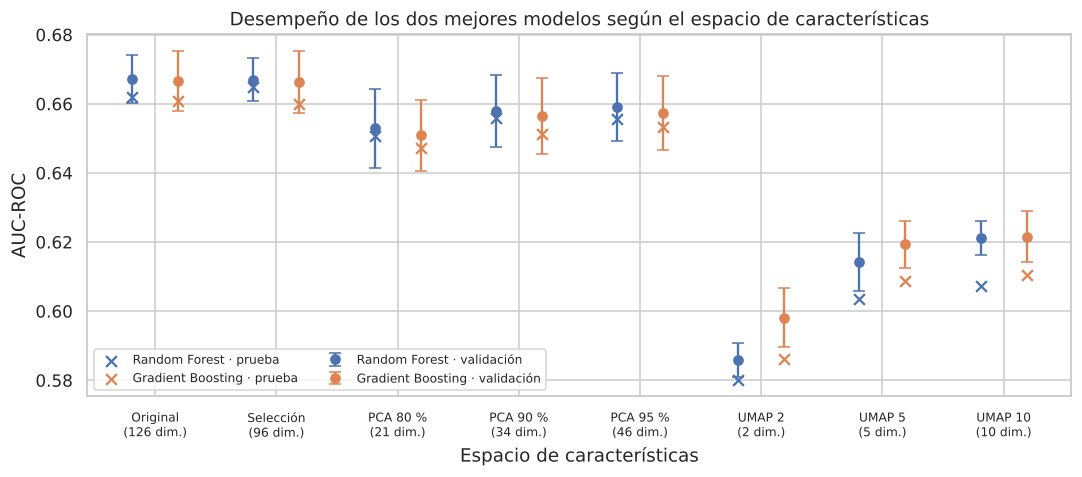

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.5))
espacios = tabla_reduccion["espacio"].unique().tolist()
ancho = 0.38
for i, nombre in enumerate(TOP2):
    d = tabla_reduccion[tabla_reduccion.modelo == nombre].set_index("espacio").loc[espacios]
    pos = np.arange(len(espacios)) + (i - 0.5) * ancho
    ax.errorbar(pos, d["AUC val."], yerr=d["IC val."], fmt="o", capsize=4, label=f"{nombre} · validación")
    ax.scatter(pos, d["AUC prueba"], marker="x", s=50, label=f"{nombre} · prueba")
ax.set_xticks(np.arange(len(espacios)))
etiquetas = [e.replace(" varianza", "").replace(" componentes", "").replace("Selección individual", "Selección")
             for e in espacios]
ax.set_xticklabels([f"{et}\n({int(tabla_reduccion[tabla_reduccion.espacio == e]['dimensiones'].iloc[0])} dim.)"
                    for et, e in zip(etiquetas, espacios)], fontsize=8)
ax.set_xlabel("Espacio de características"); ax.set_ylabel("AUC-ROC")
ax.set_title("Desempeño de los dos mejores modelos según el espacio de características")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "reduccion_dimension.pdf"), bbox_inches="tight")
plt.savefig(os.path.join(FIG_DIR, "reduccion_dimension.png"), dpi=150, bbox_inches="tight")
plt.show()

## 8. Guardar resultados

In [20]:
analisis.to_csv(os.path.join(RES_DIR, "analisis_individual.csv"), index=False)
pares.to_csv(os.path.join(RES_DIR, "redundancia_categoricas.csv"), index=False)
tabla_reduccion.to_csv(os.path.join(RES_DIR, "tabla_reduccion.csv"), index=False)
pd.concat([r.assign(modelo=n, espacio=e, dimensiones=d) for n, e, d, r in RES_REDUCCION]).to_csv(
    os.path.join(RES_DIR, "reajuste_reduccion.csv"), index=False)
with open(os.path.join(RES_DIR, "candidatas_eliminar.json"), "w", encoding="utf-8") as f:
    json.dump({"candidatas": CANDIDATAS, "componentes_pca": N_COMP}, f, ensure_ascii=False, indent=2)
print(sorted(os.listdir(RES_DIR)))

['analisis_individual.csv', 'candidatas_eliminar.json', 'cv_gradient_boosting.csv', 'cv_k_nn.csv', 'cv_mlp.csv', 'cv_random_forest.csv', 'cv_regresion_logistica.csv', 'cv_svm_rbf.csv', 'experimento_esquemas.csv', 'experimento_pesos.csv', 'figuras', 'mejores_modelos.json', 'reajuste_reduccion.csv', 'redundancia_categoricas.csv', 'resumen_prueba.csv', 'resumen_validacion.csv', 'tabla_modelos.csv', 'tabla_reduccion.csv']


## 9. Conclusiones de la Sección 5

En el informe se discute, a partir de las tablas anteriores:

- Qué variables no aportan información individual (candidatas a eliminar) y si eliminarlas cambia el desempeño.
- Cuánta reducción permite PCA sin perder AUC, y por qué la codificación one-hot limita su eficacia.
- Si UMAP conserva la información discriminante al comprimir a muy pocas dimensiones.
- Cuál es la configuración final recomendada (desempeño frente a complejidad).